# Tutorial 9: Object Detection using SSD & YOLO in PyTorch

## Block 1: Import libraries

In [1]:
import math
import time
import random
import shutil
import zipfile
import subprocess
import sys
import xml.etree.ElementTree as ET
from pathlib import Path
import yaml
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torchvision.ops import box_iou, batched_nms
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead
from torchvision.models.detection._utils import retrieve_out_channels
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps
from google.colab import files

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
print('Device:', device)

Device: cuda


## Block 2: SSD Step 1 - Define the backbone network

In [2]:
def build_ssd_backbone():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU()
    )


print(build_ssd_backbone())

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
)


## Block 3: SSD Step 2 - Define the SSD prediction head

In [3]:
class SSDHead(nn.Module):
    def __init__(self, in_channels, num_classes, num_boxes):
        super().__init__()
        self.num_classes = num_classes
        self.class_head = nn.Conv2d(in_channels, num_boxes * num_classes, 3, padding=1)
        self.box_head = nn.Conv2d(in_channels, num_boxes * 4, 3, padding=1)  # 4 values for (x, y, w, h)

    def forward(self, x):
        n = x.shape[0]
        # (N, boxes*C, H, W) -> (N, H, W, boxes*C) -> (N, H*W*boxes, C), the same as Keras' Reshape((-1, C))
        class_head = self.class_head(x).permute(0, 2, 3, 1).reshape(n, -1, self.num_classes)
        box_head = self.box_head(x).permute(0, 2, 3, 1).reshape(n, -1, 4)
        return class_head, box_head

## Block 4: SSD Step 3 - Multi-scale feature maps

In [4]:
class SSD(nn.Module):
    def __init__(self, num_classes=21, num_boxes=6, num_scales=3, backbone=None, channels=128, batch_norm=False):
        super().__init__()
        self.num_boxes = num_boxes
        self.backbone = backbone if backbone is not None else build_ssd_backbone()
        # One prediction head per scale
        self.heads = nn.ModuleList([SSDHead(channels, num_classes, num_boxes) for _ in range(num_scales)])
        # Downsample the feature map for the next scale (Conv 128, 3x3, stride 2)
        downsample = []
        for _ in range(num_scales - 1):
            layers = [nn.Conv2d(channels, channels, 3, stride=2, padding=1)]
            if batch_norm:
                layers += [nn.BatchNorm2d(channels), nn.ReLU()]
            downsample.append(nn.Sequential(*layers))
        self.downsample = nn.ModuleList(downsample)

    def forward(self, x):
        x = self.backbone(x)  # starting feature map from the backbone
        class_outputs, box_outputs = [], []
        for i, head in enumerate(self.heads):
            class_head, box_head = head(x)
            class_outputs.append(class_head)
            box_outputs.append(box_head)
            if i < len(self.downsample):
                x = self.downsample[i](x)
        # Concatenate outputs across all scales
        return torch.cat(class_outputs, dim=1), torch.cat(box_outputs, dim=1)

    def feature_sizes(self, image_size):
        # Size of the feature map at each scale
        was_training = self.training
        self.eval()
        sizes = []
        with torch.no_grad():
            x = self.backbone(torch.zeros(1, 3, image_size, image_size, device=next(self.parameters()).device))
            for i in range(len(self.heads)):
                sizes.append(x.shape[-1])
                if i < len(self.downsample):
                    x = self.downsample[i](x)
        self.train(was_training)
        return sizes


def summary(model, input_size):
    # Output shape and parameters of every layer, like Keras' model.summary()
    rows, hooks = [], []

    def hook(module, inputs, output):
        out = output[0] if isinstance(output, (tuple, list)) else output
        rows.append((module.__class__.__name__, tuple(out.shape), sum(p.numel() for p in module.parameters())))

    for m in model.modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(hook))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, input_size, input_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks:
        h.remove()

    print(f"{'Layer':16} {'Output shape':>24} {'Params':>12}")
    for name, shape, params in rows:
        print(f"{name:16} {str(shape):>24} {params:12,}")
    print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")


ssd_model = SSD(num_classes=21, num_boxes=6).to(device)
summary(ssd_model, 300)

Layer                        Output shape       Params
Conv2d                  (1, 32, 300, 300)          896
ReLU                    (1, 32, 300, 300)            0
MaxPool2d               (1, 32, 150, 150)            0
Conv2d                  (1, 64, 150, 150)       18,496
ReLU                    (1, 64, 150, 150)            0
MaxPool2d                 (1, 64, 75, 75)            0
Conv2d                   (1, 128, 75, 75)       73,856
ReLU                     (1, 128, 75, 75)            0
Conv2d                   (1, 126, 75, 75)      145,278
Conv2d                    (1, 24, 75, 75)       27,672
Conv2d                   (1, 128, 38, 38)      147,584
Conv2d                   (1, 126, 38, 38)      145,278
Conv2d                    (1, 24, 38, 38)       27,672
Conv2d                   (1, 128, 19, 19)      147,584
Conv2d                   (1, 126, 19, 19)      145,278
Conv2d                    (1, 24, 19, 19)       27,672
Total parameters: 907,266


## Block 5: SSD Step 4 - Generate dummy data for testing

In [5]:
ssd_input = torch.rand(1, 3, 300, 300, device=device)
ssd_model.eval()
with torch.no_grad():
    ssd_class_pred, ssd_box_pred = ssd_model(ssd_input)

print("SSD Class Prediction Shape:", tuple(ssd_class_pred.shape))
print("SSD Box Prediction Shape:", tuple(ssd_box_pred.shape))

sizes = ssd_model.feature_sizes(300)
print("Feature map sizes:", ' + '.join(f'{s}x{s}' for s in sizes),
      f"-> ({' + '.join(f'{s * s:,}' for s in sizes)}) cells x 6 boxes = {sum(s * s for s in sizes) * 6:,} boxes")

SSD Class Prediction Shape: (1, 44580, 21)
SSD Box Prediction Shape: (1, 44580, 4)
Feature map sizes: 75x75 + 38x38 + 19x19 -> (5,625 + 1,444 + 361) cells x 6 boxes = 44,580 boxes


## Block 6: YOLO Step 1 - Define the backbone (feature extractor)

In [6]:
def build_yolo_backbone():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(256, 512, 3, padding=1), nn.ReLU(),
        nn.MaxPool2d(2)
    )


print(build_yolo_backbone())

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)


## Block 7: YOLO Step 2 - Define the YOLO head (detection layer)

In [7]:
class YOLOHead(nn.Module):
    def __init__(self, in_channels, num_classes, num_boxes):
        super().__init__()
        self.num_classes = num_classes
        self.num_boxes = num_boxes
        # Number of output channels: num_boxes * (5 + num_classes)
        # 5 = 4 bounding box coordinates (x, y, w, h) + 1 confidence score
        num_outputs = num_boxes * (num_classes + 5)
        self.conv = nn.Conv2d(in_channels, num_outputs, 1)

    def forward(self, x):
        n, _, h, w = x.shape
        y = self.conv(x).permute(0, 2, 3, 1)  # (N, 13, 13, boxes * (5 + C))
        return y.reshape(n, h, w, self.num_boxes, self.num_classes + 5)

## Block 8: YOLO Step 3 - Combine the backbone and YOLO head

In [8]:
class YOLO(nn.Module):
    def __init__(self, num_classes=20, num_boxes=3, backbone=None, channels=512):
        super().__init__()
        self.backbone = backbone if backbone is not None else build_yolo_backbone()
        self.head = YOLOHead(channels, num_classes, num_boxes)

    def forward(self, x):
        return self.head(self.backbone(x))


yolo_model = YOLO(num_classes=20, num_boxes=3).to(device)
summary(yolo_model, 416)

Layer                        Output shape       Params
Conv2d                  (1, 32, 416, 416)          896
ReLU                    (1, 32, 416, 416)            0
MaxPool2d               (1, 32, 208, 208)            0
Conv2d                  (1, 64, 208, 208)       18,496
ReLU                    (1, 64, 208, 208)            0
MaxPool2d               (1, 64, 104, 104)            0
Conv2d                 (1, 128, 104, 104)       73,856
ReLU                   (1, 128, 104, 104)            0
MaxPool2d                (1, 128, 52, 52)            0
Conv2d                   (1, 256, 52, 52)      295,168
ReLU                     (1, 256, 52, 52)            0
MaxPool2d                (1, 256, 26, 26)            0
Conv2d                   (1, 512, 26, 26)    1,180,160
ReLU                     (1, 512, 26, 26)            0
MaxPool2d                (1, 512, 13, 13)            0
Conv2d                    (1, 75, 13, 13)       38,475
Total parameters: 1,607,051


## Block 9: YOLO Step 4 - Generate dummy data for testing

In [9]:
dummy_input = torch.rand(1, 3, 416, 416, device=device)
yolo_model.eval()
with torch.no_grad():
    yolo_pred = yolo_model(dummy_input)

print("YOLO Prediction Shape:", tuple(yolo_pred.shape))
print("13 x 13 grid cells x 3 boxes =", 13 * 13 * 3, "boxes, each with 4 coordinates + 1 confidence + 20 class scores")

YOLO Prediction Shape: (1, 13, 13, 3, 25)
13 x 13 grid cells x 3 boxes = 507 boxes, each with 4 coordinates + 1 confidence + 20 class scores


## Block 10: Tasks - Read the boxes drawn on the images

In [10]:
# Reads the boxes back from images that have labelled boxes drawn on them
# (e.g. Annotated_Images.zip): every class was drawn in its own exact colour with a name tag,
# so each tag is found by exact template matching and its rectangle is traced from the line pixels.
# The drawings are then painted out (inpainting) so the detectors are tested on clean pictures.
# Colours used when the boxes were drawn (RGB), one per class
CLASS_COLORS = {
    'trafficlight': (255, 193, 7),
    'stop': (220, 53, 69),
    'speedlimit': (0, 123, 255),
    'crosswalk': (40, 167, 69),
}


def draw_style(shape):
    h, w = shape[:2]
    return max(2, round(min(h, w) / 150)), max(0.4, min(h, w) / 600)


def tag_size(name, shape):
    _, fs = draw_style(shape)
    (tw, th), base = cv2.getTextSize(name, cv2.FONT_HERSHEY_SIMPLEX, fs, 1)
    return tw, th, base


def draw_box(canvas, name, x1, y1, x2, y2, color, outline=True, tag=True):
    # Same drawing routine that produced the annotated images
    t, fs = draw_style(canvas.shape)
    tw, th, base = tag_size(name, canvas.shape)
    if outline:
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, t)
    if tag:
        ty = max(y1, th + base + 4)
        cv2.rectangle(canvas, (x1, ty - th - base - 4), (x1 + tw + 6, ty), color, -1)
        cv2.putText(canvas, name, (x1 + 3, ty - base - 2), cv2.FONT_HERSHEY_SIMPLEX,
                    fs, (255, 255, 255), 1, cv2.LINE_AA)


def tag_template(name, color, shape):
    tw, th, base = tag_size(name, shape)
    th_tag = th + base + 4
    tmpl = np.zeros(shape, np.uint8)
    draw_box(tmpl, name, 0, th_tag, 1, th_tag + 1, color, outline=False)
    return (tmpl[:th_tag + 1, :tw + 7] == np.array(color, np.uint8)).all(-1).astype(np.float32), th_tag


def find_all_tags(img):
    # Locate every label tag by matching the exact rendered tag. Tags already found (and other
    # classes' drawings) are treated as wildcards, so a tag partly hidden under another is still found.
    h, w = img.shape[:2]
    masks = {n: (img == np.array(c, np.uint8)).all(-1) for n, c in CLASS_COLORS.items()}
    any_col = np.zeros((h, w), bool)
    for m in masks.values():
        any_col |= m
    found = []
    W = np.zeros((h, w), np.float32)  # wildcard pixels: covered by a tag found earlier
    while True:
        best = None
        for name, color in CLASS_COLORS.items():
            if not masks[name].any():
                continue
            F, th_tag = tag_template(name, color, img.shape)
            th_, tw_ = F.shape
            E = masks[name].astype(np.float32)
            wild = np.maximum(W, (any_col & ~masks[name]).astype(np.float32))
            P = lambda a: cv2.copyMakeBorder(a, 0, th_, 0, tw_, cv2.BORDER_CONSTANT, value=0)
            K = P((1 - wild))            # pixels inside the image that are not wildcards
            Ek = P(E * (1 - wild))
            agree = cv2.matchTemplate(Ek, F, cv2.TM_CCORR) + cv2.matchTemplate(K - Ek, 1 - F, cv2.TM_CCORR)
            known = cv2.matchTemplate(K, np.ones_like(F), cv2.TM_CCORR)
            ratio = np.where(known >= 0.25 * F.size, agree / np.maximum(known, 1), 0)
            y, x = np.unravel_index(np.argmax(ratio), ratio.shape)
            if ratio[y, x] >= 0.92 and (best is None or known[y, x] > best[0]):
                best = (known[y, x], name, int(x), int(y), th_tag, tw_, th_)
        if best is None:
            break
        _, name, x, y, th_tag, tw_, th_ = best
        found.append((name, x, y + th_tag))  # (class, x1, bottom row of the tag)
        W[y:y + th_, x:x + tw_] = 1
    return found


def run_end(line, start):
    # last index of the run of True values that begins at `start`
    i = start
    while i + 1 < len(line) and line[i + 1]:
        i += 1
    return i if line[start] else None


def best_box(mask, covered, free, name, color, shape, x1, y1_options, x2s, y2s, min_y2):
    # Smallest rectangle whose drawn outline is fully supported by the image
    h, w = shape[:2]
    best = None
    for y1 in y1_options:
        cands = sorted(((x2, y2) for x2 in set(x2s) for y2 in set(y2s)
                        if x2 > x1 + 2 and y2 > max(y1 + 2, min_y2)),
                       key=lambda b: (b[0] - x1) * (b[1] - y1))
        for x2, y2 in cands:
            if best is not None and (x2 - x1) * (y2 - y1) >= best[0]:
                break
            canvas = np.zeros(shape, np.uint8)
            draw_box(canvas, name, x1, y1, x2, y2, color, tag=False)
            out = (canvas == np.array(color, np.uint8)).all(-1)
            n = np.count_nonzero(out)
            if n == 0:
                continue
            if np.count_nonzero(out & mask & free) < 0.3 * n:   # a good part must be visibly drawn in this colour
                continue
            if np.count_nonzero(out & covered) >= 0.95 * n:
                best = ((x2 - x1) * (y2 - y1), (x1, y1, min(x2, w - 1), min(y2, h - 1)))
                break
    return best[1] if best else None


def edge_candidates(covered, mask, other_tags, x1, y1, t, shape):
    h, w = shape[:2]
    k = max(4, 2 * t)
    r0, r1 = min(h - 1, y1 + t + 1), min(h, y1 + t + 1 + k)
    c0, c1 = min(w - 1, x1 + t + 1), min(w, x1 + t + 1 + k)
    vert = [covered[r0:r1, c].all() for c in range(w)]
    horz = [covered[r, c0:c1].all() for r in range(h)]
    x2s = [c for c in range(x1 + 3, w) if vert[c] and (c + 1 >= w or not vert[c + 1])]
    y2s = [r for r in range(y1 + 3, h) if horz[r] and (r + 1 >= h or not horz[r + 1])]
    x2s = [c - d for c in x2s for d in range(t + 1)] + [w + 50]
    y2s = [r - d for r in y2s for d in range(t + 1)] + [h + 50]
    for m in (mask, covered):  # where the top edge and the left edge stop
        e = run_end(m[min(h - 1, y1), :], x1) if 0 <= y1 < h else None
        if e is not None:
            x2s += [e - d for d in range(t + 1)]
        e = run_end(m[:, x1], max(0, y1))
        if e is not None:
            y2s += [e - d for d in range(t + 1)]
    # edges hidden under other tags
    ys, xs = np.nonzero(other_tags[:, x1:x1 + 1])
    y2s += [int(y) for y in ys if y > y1 + 2]
    if 0 <= y1 < h:
        xs = np.nonzero(other_tags[y1])[0]
        x2s += [int(x) for x in xs if x > x1 + 2]
    return x2s, y2s


def fit_from_tag(img, mask, covered, free, other_tags, name, color, x1, ty, own_tag):
    t, _ = draw_style(img.shape)
    tw, th, base = tag_size(name, img.shape)
    th_tag = th + base + 4
    y1_options = [ty] if ty > th_tag else list(range(0, th_tag + 1))
    best = None
    for y1 in y1_options:
        x2s, y2s = edge_candidates(covered | own_tag, mask, other_tags, x1, y1, t, img.shape)
        box = best_box(mask, covered | own_tag, free, name, color, img.shape,
                       x1, [y1], x2s, y2s, ty + t)
        if box and (best is None or (box[2] - box[0]) * (box[3] - box[1]) < best[0]):
            best = ((box[2] - box[0]) * (box[3] - box[1]), box)
    return best[1] if best else None


def fit_untagged(img, comp, covered, free, other_tags, name, color):
    # Box whose tag is hidden under another tag: start from the lowest visible edge
    h, w = img.shape[:2]
    t, _ = draw_style(img.shape)
    ys, xs = np.nonzero(comp)
    y_bot = ys.max()
    row = xs[ys == y_bot]
    x1, x2 = int(row.min()), int(row.max())
    y2 = int(min(y_bot, h - 1) - t // 2) if y_bot < h - 1 else h + 50
    return best_box(comp, covered, free, name, color, img.shape, x1,
                    range(max(0, int(ys.min()) - 2 * t), y2 - 2), [x2, x2 + 1, x2 - 1], [y2], 0)


def refine(box, mask, covered, tags_area, name, color, shape, move_x1=False, move_y1=False):
    # Nudge the box edges by a pixel or two to best match the drawn line pixels
    h, w = shape[:2]
    t, _ = draw_style(shape)
    x1, y1, x2, y2 = box
    r0, r1 = max(0, y1 - 3 * t), min(h, y2 + 3 * t + 1)
    c0, c1 = max(0, x1 - 3 * t), min(w, x2 + 3 * t + 1)
    target = mask[r0:r1, c0:c1] & ~tags_area[r0:r1, c0:c1]
    cov = covered[r0:r1, c0:c1]
    R = range(-t, t + 1)
    best = None
    for a in (R if move_x1 else [0]):
        for b in (R if move_y1 else [0]):
            for c in R:
                for d in R:
                    bx = (x1 + a, y1 + b, x2 + c, y2 + d)
                    if bx[2] <= bx[0] + 2 or bx[3] <= bx[1] + 2:
                        continue
                    canvas = np.zeros(shape, np.uint8)
                    draw_box(canvas, name, *bx, color, tag=False)
                    out = (canvas == np.array(color, np.uint8)).all(-1)[r0:r1, c0:c1]
                    score = (np.count_nonzero(out & target) - 3 * np.count_nonzero(out & ~cov)
                             - np.count_nonzero(target & ~out))
                    if best is None or score > best[0]:
                        best = (score, bx)
    x1, y1, x2, y2 = best[1]
    return (max(0, x1), max(0, y1), min(w - 1, x2), min(h - 1, y2))


def recover_boxes(img):
    # img: RGB image with boxes drawn on it -> list of (class name, (xmin, ymin, xmax, ymax))
    h, w = img.shape[:2]
    masks = {n: (img == np.array(c, np.uint8)).all(-1) for n, c in CLASS_COLORS.items()}
    tags = find_all_tags(img)
    all_tags = np.zeros((h, w), bool)
    regions = []
    for name, x1, ty in tags:
        tw, th, base = tag_size(name, img.shape)
        r = np.zeros((h, w), bool)
        r[max(0, ty - th - base - 4):ty + 1, x1:x1 + tw + 7] = True
        regions.append(r)
        all_tags |= r
    objects = []
    explained = all_tags.copy()
    for (name, x1, ty), own in zip(tags, regions):
        color = CLASS_COLORS[name]
        other = all_tags & ~own
        for n2, m2 in masks.items():
            if n2 != name:
                other |= m2
        box = fit_from_tag(img, masks[name], masks[name] | other, ~other, all_tags & ~own,
                           name, color, x1, ty, own)
        if box:
            tw, th, base = tag_size(name, img.shape)
            box = refine(box, masks[name], masks[name] | other | own, all_tags, name, color, img.shape,
                         move_y1=ty <= th + base + 4)
            objects.append((name, box))
            canvas = np.zeros(img.shape, np.uint8)
            draw_box(canvas, name, *box, color, tag=False)
            explained |= (canvas == np.array(color, np.uint8)).all(-1)
    # boxes whose tag was hidden: colour pixels that no box explains yet
    explained = cv2.dilate(explained.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
    for name, color in CLASS_COLORS.items():
        left = masks[name] & ~explained
        n, labels, stats, _ = cv2.connectedComponentsWithStats(left.astype(np.uint8), connectivity=8)
        for i in range(1, n):
            if stats[i, cv2.CC_STAT_AREA] < 40:
                continue
            other = all_tags.copy()
            for n2, m2 in masks.items():
                if n2 != name:
                    other |= m2
            box = fit_untagged(img, labels == i, masks[name] | other | explained, ~other, all_tags, name, color)
            if box:
                box = refine(box, masks[name], masks[name] | other | explained, all_tags, name, color,
                             img.shape, move_x1=True, move_y1=True)
                objects.append((name, box))
    return objects


def clean_image(img, objects):
    # Paint over the drawn boxes and tags so the detectors see the original picture
    h, w = img.shape[:2]
    any_col = np.zeros((h, w), bool)
    for c in CLASS_COLORS.values():
        any_col |= (img == np.array(c, np.uint8)).all(-1)
    footprint = np.zeros((h, w), np.uint8)
    for name, box in objects:
        canvas = np.zeros(img.shape, np.uint8)
        draw_box(canvas, name, *box, CLASS_COLORS[name])
        footprint |= canvas.any(-1).astype(np.uint8)
    footprint = cv2.dilate(footprint | any_col.astype(np.uint8), np.ones((3, 3), np.uint8))
    return cv2.inpaint(img, footprint, 3, cv2.INPAINT_TELEA)

## Block 11: Tasks - Upload and read the labelled dataset

In [11]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
MAX_IMAGES = 150   # how many labelled images to use (None = all)
SEED = 42          # same seed = same images every run


def open_image(path):
    # exif_transpose rotates phone photos the same way labelling tools display them
    return ImageOps.exif_transpose(Image.open(path)).convert('RGB')


def read_yolo_names(root):
    # Class names from classes.txt / obj.names / data.yaml (Roboflow, LabelImg, makesense)
    for txt in list(root.rglob('classes.txt')) + list(root.rglob('*.names')):
        names = [line.strip() for line in open(txt) if line.strip()]
        if names:
            return names
    for yml in list(root.rglob('data.yaml')) + list(root.rglob('*.yaml')):
        try:
            names = yaml.safe_load(open(yml)).get('names')
        except Exception:
            continue
        if isinstance(names, dict):
            names = [names[k] for k in sorted(names)]
        if names:
            return [str(n) for n in names]
    return []


def pick(paths):
    # random but repeatable subset
    paths = sorted(paths)
    random.Random(SEED).shuffle(paths)
    return paths


def load_labelled_zip(zip_path, extract_dir):
    shutil.rmtree(extract_dir, ignore_errors=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(extract_dir)
    root = Path(extract_dir)

    def usable(p):
        return '__MACOSX' not in p.parts and not p.name.startswith('.')

    images = {p.stem: p for p in root.rglob('*') if p.suffix.lower() in IMAGE_EXTS and usable(p)}
    xml_files = [p for p in root.rglob('*.xml') if usable(p)]
    txt_files = [p for p in root.rglob('*.txt') if usable(p) and p.name not in ('classes.txt', 'README.txt')]
    samples, skipped = [], 0
    enough = lambda: MAX_IMAGES is not None and len(samples) >= MAX_IMAGES

    if xml_files:
        label_format = 'Pascal VOC (.xml)'
        for xml_path in pick(xml_files):
            if enough():
                break
            ann = ET.parse(xml_path).getroot()
            img_path = images.get(xml_path.stem) or images.get(Path(ann.findtext('filename', '')).stem)
            if img_path is None:
                skipped += 1
                continue
            width, height = open_image(img_path).size
            xml_w = float(ann.findtext('size/width') or 0) or width
            xml_h = float(ann.findtext('size/height') or 0) or height
            sx, sy = width / xml_w, height / xml_h  # in case the image was resized after labelling
            objects = []
            for obj in ann.iter('object'):
                bb = obj.find('bndbox')
                x1, y1, x2, y2 = (float(bb.findtext(k)) for k in ('xmin', 'ymin', 'xmax', 'ymax'))
                box = [max(0, x1 * sx), max(0, y1 * sy), min(width, x2 * sx), min(height, y2 * sy)]
                if box[2] - box[0] > 1 and box[3] - box[1] > 1:
                    objects.append((obj.findtext('name').strip(), box))
            samples.append((img_path, objects))
    elif txt_files:
        label_format = 'YOLO (.txt)'
        names = read_yolo_names(root)
        for txt_path in pick(txt_files):
            if enough():
                break
            img_path = images.get(txt_path.stem)
            if img_path is None:
                skipped += 1
                continue
            width, height = open_image(img_path).size
            objects = []
            for line in open(txt_path):
                values = line.split()
                if len(values) < 5:
                    continue
                cls = int(float(values[0]))
                xc, yc, bw, bh = (float(v) for v in values[1:5])
                box = [max(0, (xc - bw / 2) * width), max(0, (yc - bh / 2) * height),
                       min(width, (xc + bw / 2) * width), min(height, (yc + bh / 2) * height)]
                if box[2] - box[0] > 1 and box[3] - box[1] > 1:
                    name = names[cls] if cls < len(names) else f'class_{cls}'
                    objects.append((name.strip(), box))
            samples.append((img_path, objects))
    elif images:
        # No label files: read the boxes from the colours drawn on the images
        label_format = 'boxes drawn on the images (read from their colours)'
        clean_dir = root / '_clean'
        clean_dir.mkdir(exist_ok=True)
        todo = pick(list(images.values()))
        print(f'Reading the drawn boxes from {len(todo)} images...')
        for k, img_path in enumerate(todo):
            if enough():
                break
            img = np.array(open_image(img_path))
            objects = recover_boxes(img)
            if not objects:
                skipped += 1
                continue
            clean_path = clean_dir / (img_path.stem + '.png')
            Image.fromarray(clean_image(img, objects)).save(clean_path)
            samples.append((clean_path, [(name, [float(v) for v in box]) for name, box in objects]))
            if (k + 1) % 25 == 0:
                print(f'  {k + 1} images done')
    else:
        raise ValueError('No images or label files found in the zip.')

    if not samples:
        raise ValueError('No labelled images found. Use a zip with images + .xml/.txt label files, or '
                         'images with the boxes drawn on them.')

    print('Label format:', label_format)
    print('Labelled images used:', len(samples))
    if skipped:
        print('Images skipped (no labels found):', skipped)
    counts = {}
    for _, objects in samples:
        for name, _ in objects:
            counts[name] = counts.get(name, 0) + 1
    for name, n in sorted(counts.items()):
        print(f'  {name}: {n} objects')
    return samples


# Upload the same zip as Tutorial 8 (images with the boxes drawn on them, or images + .xml/.txt labels)
uploaded = files.upload()
zip_name = next(name for name in uploaded if name.lower().endswith('.zip'))
samples = load_labelled_zip(zip_name, '/content/dataset')

class_names = sorted({name for _, objects in samples for name, _ in objects})
class_to_id = {name: i + 1 for i, name in enumerate(class_names)}  # 0 is background
print('Classes:', class_names)

random.Random(42).shuffle(samples)
split = int(0.8 * len(samples))
train_samples, test_samples = samples[:split], samples[split:]
print('Training images:', len(train_samples))
print('Test images:', len(test_samples))
for name in class_names:
    n_train = sum(1 for _, objs in train_samples for n, _ in objs if n == name)
    n_test = sum(1 for _, objs in test_samples for n, _ in objs if n == name)
    print(f"  {name:14} train: {n_train:4}   test: {n_test:4}")

# Ground truth of the test images, in pixels of the original images
test_ground_truths = [{'boxes': [box for _, box in objects], 'labels': [class_to_id[n] for n, _ in objects]}
                      for _, objects in test_samples]

Saving Annotated Images.zip to Annotated Images.zip
Reading the drawn boxes from 150 images...
  25 images done
  50 images done
  75 images done
  100 images done
  125 images done
  150 images done
Label format: boxes drawn on the images (read from their colours)
Labelled images used: 149
Images skipped (no labels found): 1
  crosswalk: 34 objects
  speedlimit: 123 objects
  stop: 17 objects
  trafficlight: 19 objects
Classes: ['crosswalk', 'speedlimit', 'stop', 'trafficlight']
Training images: 119
Test images: 30
  crosswalk      train:   26   test:    8
  speedlimit     train:  101   test:   22
  stop           train:   13   test:    4
  trafficlight   train:   16   test:    3


## Block 12: Tasks - Datasets and data loaders

From-scratch SSD data: (119, 3, 300, 300) (30, 3, 300, 300)
From-scratch YOLO data: (119, 3, 416, 416) (30, 3, 416, 416)


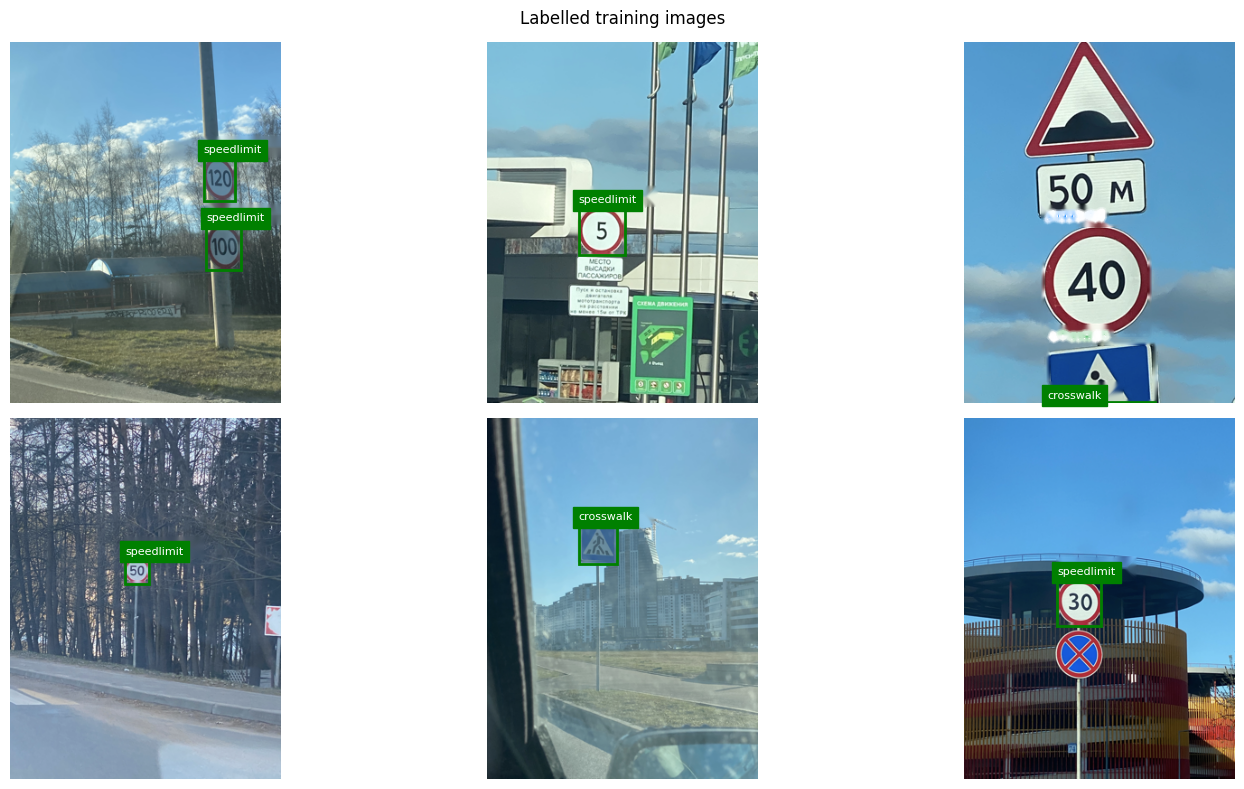

In [12]:
def draw_boxes(ax, boxes, texts, color):
    for box, text in zip(boxes, texts):
        x1, y1, x2, y2 = box
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
        ax.text(x1, y1 - 3, text, color='white', fontsize=8, backgroundcolor=color)


# a) Full-size images for the pretrained SSD (Task 2), same as Tutorial 8
class DetectionDataset(Dataset):
    def __init__(self, samples, train=False):
        self.samples = samples
        self.train = train

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, objects = self.samples[idx]
        image = TF.to_tensor(open_image(img_path))
        boxes = torch.tensor([box for _, box in objects], dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor([class_to_id[name] for name, _ in objects], dtype=torch.int64)
        if self.train and random.random() < 0.5:  # random horizontal flip
            image = image.flip(-1)
            width = image.shape[-1]
            boxes[:, [0, 2]] = width - boxes[:, [2, 0]]
        return image, {'boxes': boxes, 'labels': labels}


def collate_fn(batch):
    return tuple(zip(*batch))


train_loader = DataLoader(DetectionDataset(train_samples, train=True), batch_size=8, shuffle=True,
                          num_workers=2, collate_fn=collate_fn)
test_loader = DataLoader(DetectionDataset(test_samples), batch_size=8, shuffle=False,
                         num_workers=2, collate_fn=collate_fn)


# b) Square, resized images kept in memory for the from-scratch SSD (300x300) and YOLO (416x416).
#    Boxes are stored as fractions of the image size (0 to 1).
def load_resized(samples, size):
    images, targets = [], []
    for img_path, objects in samples:
        img = open_image(img_path)
        w, h = img.size
        images.append(torch.from_numpy(np.array(img.resize((size, size), Image.BILINEAR))).permute(2, 0, 1))
        boxes = torch.tensor([[x1 / w, y1 / h, x2 / w, y2 / h] for _, (x1, y1, x2, y2) in objects],
                             dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor([class_to_id[name] for name, _ in objects], dtype=torch.int64)
        targets.append({'boxes': boxes, 'labels': labels, 'size': (w, h)})
    return torch.stack(images), targets


def batches(images, targets, batch_size, augment=False):
    order = torch.randperm(len(images)).tolist() if augment else list(range(len(images)))
    for k in range(0, len(order), batch_size):
        ids = order[k:k + batch_size]
        x = images[ids].float().div(255)
        t = [{'boxes': targets[i]['boxes'].clone(), 'labels': targets[i]['labels']} for i in ids]
        if augment:
            for j in range(len(ids)):
                if random.random() < 0.5:  # horizontal flip
                    x[j] = x[j].flip(-1)
                    bx = t[j]['boxes']
                    t[j]['boxes'] = torch.stack([1 - bx[:, 2], bx[:, 1], 1 - bx[:, 0], bx[:, 3]], dim=1)
                x[j] = (x[j] * random.uniform(0.75, 1.25)).clamp(0, 1)  # brightness
        yield x.to(device), t


ssd_train, ssd_test = load_resized(train_samples, 300), load_resized(test_samples, 300)
yolo_train, yolo_test = load_resized(train_samples, 416), load_resized(test_samples, 416)
print('From-scratch SSD data:', tuple(ssd_train[0].shape), tuple(ssd_test[0].shape))
print('From-scratch YOLO data:', tuple(yolo_train[0].shape), tuple(yolo_test[0].shape))

plt.figure(figsize=(16, 8))
for i in range(min(6, len(train_samples))):
    image, target = DetectionDataset(train_samples)[i]
    ax = plt.subplot(2, 3, i + 1)
    ax.imshow(image.permute(1, 2, 0))
    draw_boxes(ax, target['boxes'].tolist(), [class_names[l - 1] for l in target['labels'].tolist()], 'green')
    ax.axis('off')
plt.suptitle('Labelled training images')
plt.tight_layout()
plt.show()

## Block 13: Tasks - Evaluation functions (IoU, AP, precision, recall, mAP)

In [13]:
def calculate_iou(box1, box2):
    xmin1, ymin1, xmax1, ymax1 = box1
    xmin2, ymin2, xmax2, ymax2 = box2
    inter_area = max(0, min(xmax1, xmax2) - max(xmin1, xmin2)) * max(0, min(ymax1, ymax2) - max(ymin1, ymin2))
    area1 = (xmax1 - xmin1) * (ymax1 - ymin1)
    area2 = (xmax2 - xmin2) * (ymax2 - ymin2)
    union_area = area1 + area2 - inter_area
    return inter_area / union_area if union_area != 0 else 0


def calculate_ap(precisions, recalls):
    precisions = [0.0] + precisions + [0.0]
    recalls = [0.0] + recalls + [1.0]
    for i in range(len(precisions) - 1, 0, -1):
        precisions[i - 1] = max(precisions[i - 1], precisions[i])
    indices = [i for i in range(1, len(recalls)) if recalls[i] != recalls[i - 1]]
    return sum((recalls[i] - recalls[i - 1]) * precisions[i] for i in indices)


def evaluate_class(predictions, ground_truths, class_id, iou_threshold=0.5, score_threshold=0.5):
    # Ranks every detection of one class by score and uses calculate_iou and calculate_ap from above
    detections, gt_by_image, n_gt = [], {}, 0
    for i, (pred, gt) in enumerate(zip(predictions, ground_truths)):
        gt_by_image[i] = [box for box, l in zip(gt['boxes'], gt['labels']) if l == class_id]
        n_gt += len(gt_by_image[i])
        detections += [(s, i, box) for box, s, l in zip(pred['boxes'], pred['scores'], pred['labels']) if l == class_id]
    if n_gt == 0:
        return None

    detections.sort(key=lambda d: -d[0])
    matched = {i: set() for i in gt_by_image}
    tp = fp = 0
    precisions, recalls = [], []
    precision_at, recall_at = 0.0, 0.0
    for score, i, box in detections:
        best_iou, best_j = 0, -1
        for j, gt_box in enumerate(gt_by_image[i]):
            if j not in matched[i]:
                iou = calculate_iou(box, gt_box)
                if iou > best_iou:
                    best_iou, best_j = iou, j
        if best_iou >= iou_threshold:
            tp += 1
            matched[i].add(best_j)
        else:
            fp += 1
        precisions.append(tp / (tp + fp))
        recalls.append(tp / n_gt)
        if score >= score_threshold:
            precision_at, recall_at = precisions[-1], recalls[-1]

    return calculate_ap(precisions, recalls), precision_at, recall_at, n_gt


results, all_predictions = {}, {}


def report(name, predictions, params, train_time):
    print(f"\n{name}")
    print(f"{'Class':14} {'Objects':>8} {'AP@0.5':>8} {'AP@0.75':>8} {'Precision':>10} {'Recall':>8}")
    ap50, ap75 = {}, {}
    for cname in class_names:
        cid = class_to_id[cname]
        r50 = evaluate_class(predictions, test_ground_truths, cid, iou_threshold=0.5)
        r75 = evaluate_class(predictions, test_ground_truths, cid, iou_threshold=0.75)
        if r50 is None:
            continue
        ap50[cname], ap75[cname] = r50[0], r75[0]
        print(f"{cname:14} {r50[3]:8} {r50[0]:8.3f} {r75[0]:8.3f} {r50[1]:10.3f} {r50[2]:8.3f}")
    map50, map75 = float(np.mean(list(ap50.values()))), float(np.mean(list(ap75.values())))
    print(f"mAP@0.5: {map50:.3f}   mAP@0.75: {map75:.3f}   (precision and recall at score >= 0.5)")
    results[name] = {'params': params, 'map50': map50, 'map75': map75, 'time': train_time, 'ap50': ap50}
    all_predictions[name] = predictions

## Block 14: Task 1 - SSD anchor boxes, matching, loss and prediction

In [14]:
VARIANCES = (0.1, 0.2)


def cxcywh_to_xyxy(b):
    return torch.cat([b[:, :2] - b[:, 2:] / 2, b[:, :2] + b[:, 2:] / 2], dim=1)


def xyxy_to_cxcywh(b):
    return torch.cat([(b[:, :2] + b[:, 2:]) / 2, b[:, 2:] - b[:, :2]], dim=1)


def make_ssd_anchors(feature_sizes, scales, aspect_ratios=(1.0, 2.0, 0.5, 3.0, 1 / 3)):
    # 6 anchor boxes per cell: 5 aspect ratios (width/height) at scale s, plus one extra
    # square box at scale sqrt(s * s_next). Same order as the head output: row, column, box.
    anchors = []
    for k, f in enumerate(feature_sizes):
        s, s_next = scales[k], scales[k + 1]
        for i in range(f):
            for j in range(f):
                cx, cy = (j + 0.5) / f, (i + 0.5) / f
                for ar in aspect_ratios:
                    anchors.append([cx, cy, s * math.sqrt(ar), s / math.sqrt(ar)])
                extra = math.sqrt(s * s_next)
                anchors.append([cx, cy, extra, extra])
    return torch.tensor(anchors, dtype=torch.float32).clamp(0, 1)  # (cx, cy, w, h), 0 to 1


def ssd_anchors_for(model, image_size=300):
    sizes = model.feature_sizes(image_size)
    scales = np.linspace(0.08, 0.6, len(sizes) + 1)
    anchors = make_ssd_anchors(sizes, scales).to(device)
    assert model.num_boxes == 6 and len(anchors) == sum(f * f for f in sizes) * 6
    return anchors, cxcywh_to_xyxy(anchors)


def ssd_encode(gt_xyxy, anchors):
    # Offsets of the ground-truth boxes from their anchors, which the box head learns to predict
    g = xyxy_to_cxcywh(gt_xyxy)
    t_xy = (g[:, :2] - anchors[:, :2]) / (anchors[:, 2:] * VARIANCES[0])
    t_wh = torch.log(g[:, 2:].clamp(min=1e-6) / anchors[:, 2:]) / VARIANCES[1]
    return torch.cat([t_xy, t_wh], dim=1)


def ssd_decode(t, anchors):
    xy = anchors[:, :2] + t[:, :2] * VARIANCES[0] * anchors[:, 2:]
    wh = anchors[:, 2:] * torch.exp((t[:, 2:] * VARIANCES[1]).clamp(max=6))
    return cxcywh_to_xyxy(torch.cat([xy, wh], dim=1))


def ssd_match(target, anchors, anchors_xyxy, iou_threshold=0.5):
    # Each anchor gets the class of the ground-truth box it overlaps most (IoU >= 0.5), or background (0)
    labels = torch.zeros(len(anchors), dtype=torch.long, device=device)
    locs = torch.zeros(len(anchors), 4, device=device)
    boxes = target['boxes'].to(device)
    if len(boxes) == 0:
        return labels, locs
    iou = box_iou(boxes, anchors_xyxy)          # (objects, anchors)
    best_iou, best_gt = iou.max(dim=0)           # best object for each anchor
    best_anchor = iou.argmax(dim=1)              # every object also keeps its best anchor
    best_gt[best_anchor] = torch.arange(len(boxes), device=device)
    best_iou[best_anchor] = 1.0
    pos = best_iou >= iou_threshold
    labels[pos] = target['labels'].to(device)[best_gt[pos]]
    locs[pos] = ssd_encode(boxes[best_gt[pos]], anchors[pos])
    return labels, locs


def ssd_loss(outputs, targets, anchors, anchors_xyxy):
    class_pred, box_pred = outputs
    matched = [ssd_match(t, anchors, anchors_xyxy) for t in targets]
    labels = torch.stack([m[0] for m in matched])   # (N, anchors)
    locs = torch.stack([m[1] for m in matched])     # (N, anchors, 4)
    pos = labels > 0
    num_pos = pos.sum().clamp(min=1)

    loc_loss = F.smooth_l1_loss(box_pred[pos], locs[pos], reduction='sum')
    ce = F.cross_entropy(class_pred.reshape(-1, class_pred.shape[-1]), labels.reshape(-1),
                         reduction='none').reshape(labels.shape)
    # Hard negative mining: only the background anchors with the highest loss are used (3 per object)
    neg_ce = ce.detach().clone()
    neg_ce[pos] = 0
    rank = neg_ce.argsort(dim=1, descending=True).argsort(dim=1)
    num_neg = (3 * pos.sum(dim=1, keepdim=True)).clamp(min=10, max=labels.shape[1] - 1)
    neg = (rank < num_neg) & ~pos
    cls_loss = ce[pos].sum() + ce[neg].sum()
    return (loc_loss + cls_loss) / num_pos


def ssd_predict(model, images, anchors, score_threshold=0.05, iou_threshold=0.45, top_k=100):
    model.eval()
    with torch.no_grad():
        class_pred, box_pred = model(images)
    outputs = []
    for scores, deltas in zip(class_pred.softmax(-1), box_pred):
        boxes = ssd_decode(deltas, anchors).clamp(0, 1)
        scores = scores[:, 1:]  # drop the background class
        idx, cls = (scores > score_threshold).nonzero(as_tuple=True)
        s = scores[idx, cls]
        if len(s) > 2000:
            top = s.topk(2000).indices
            idx, cls, s = idx[top], cls[top], s[top]
        keep = batched_nms(boxes[idx], s, cls, iou_threshold)[:top_k]  # non-maximum suppression
        outputs.append({'boxes': boxes[idx][keep], 'scores': s[keep], 'labels': cls[keep] + 1})
    return outputs

## Block 15: Task 1 - YOLO anchor boxes, targets, loss and prediction

In [15]:
def kmeans_anchors(targets, k=3, iterations=50):
    # Anchor sizes from the training boxes (k-means with 1 - IoU as the distance)
    wh = torch.cat([t['boxes'][:, 2:] - t['boxes'][:, :2] for t in targets]).numpy()
    rng = np.random.default_rng(42)
    centers = wh[rng.choice(len(wh), k, replace=False)]
    for _ in range(iterations):
        inter = np.minimum(wh[:, None, 0], centers[None, :, 0]) * np.minimum(wh[:, None, 1], centers[None, :, 1])
        iou = inter / (wh[:, None, 0] * wh[:, None, 1] + centers[None, :, 0] * centers[None, :, 1] - inter)
        assign = iou.argmax(axis=1)
        centers = np.array([np.median(wh[assign == c], axis=0) if (assign == c).any() else centers[c]
                            for c in range(k)])
    centers = centers[np.argsort(centers[:, 0] * centers[:, 1])]
    return torch.tensor(centers, dtype=torch.float32).to(device)


def yolo_decode_raw(raw, anchors):
    # raw: (N, S, S, boxes, 5 + C) -> boxes (x1, y1, x2, y2) from 0 to 1, confidence, class probabilities
    s = raw.shape[1]
    grid_y, grid_x = torch.meshgrid(torch.arange(s, device=raw.device), torch.arange(s, device=raw.device),
                                    indexing='ij')
    cx = (raw[..., 0].sigmoid() + grid_x[None, :, :, None]) / s
    cy = (raw[..., 1].sigmoid() + grid_y[None, :, :, None]) / s
    w = anchors[:, 0] * raw[..., 2].clamp(max=6).exp()
    h = anchors[:, 1] * raw[..., 3].clamp(max=6).exp()
    boxes = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=-1)
    return boxes, raw[..., 4].sigmoid(), raw[..., 5:].softmax(-1)


def yolo_build_targets(targets, anchors, s):
    # Each object is assigned to the grid cell containing its centre and the anchor closest to its shape
    n, nb = len(targets), anchors.shape[0]
    obj = torch.zeros(n, s, s, nb, device=device)
    txy = torch.zeros(n, s, s, nb, 2, device=device)
    twh = torch.zeros(n, s, s, nb, 2, device=device)
    cls = torch.zeros(n, s, s, nb, dtype=torch.long, device=device)
    scale = torch.zeros(n, s, s, nb, device=device)
    gt_boxes = []
    for i, t in enumerate(targets):
        boxes = t['boxes'].to(device)
        gt_boxes.append(boxes)
        for box, label in zip(boxes, t['labels'].tolist()):
            cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
            w, h = (box[2] - box[0]).clamp(min=1e-4), (box[3] - box[1]).clamp(min=1e-4)
            gx, gy = min(int(cx * s), s - 1), min(int(cy * s), s - 1)
            inter = torch.minimum(w, anchors[:, 0]) * torch.minimum(h, anchors[:, 1])
            a = int((inter / (w * h + anchors[:, 0] * anchors[:, 1] - inter)).argmax())
            obj[i, gy, gx, a] = 1
            txy[i, gy, gx, a] = torch.stack([cx * s - gx, cy * s - gy])
            twh[i, gy, gx, a] = torch.log(torch.stack([w / anchors[a, 0], h / anchors[a, 1]]))
            cls[i, gy, gx, a] = label - 1
            scale[i, gy, gx, a] = 2 - w * h  # small boxes count more
    return obj, txy, twh, cls, scale, gt_boxes


def yolo_loss(raw, targets, anchors):
    s = raw.shape[1]
    obj, txy, twh, cls, scale, gt_boxes = yolo_build_targets(targets, anchors, s)
    pos = obj > 0
    num_pos = pos.sum().clamp(min=1)

    # Predictions that already overlap an object well (IoU > 0.5) are not punished as background
    pred_boxes, _, _ = yolo_decode_raw(raw.detach(), anchors)
    ignore = torch.zeros_like(pos)
    for i, boxes in enumerate(gt_boxes):
        if len(boxes):
            ignore[i] = box_iou(pred_boxes[i].reshape(-1, 4), boxes).max(dim=1).values.reshape(pos.shape[1:]) > 0.5
    noobj = ~pos & ~ignore

    w = scale[pos].unsqueeze(1)
    xy_loss = (w * (raw[..., :2][pos].sigmoid() - txy[pos]) ** 2).sum()
    wh_loss = (w * (raw[..., 2:4][pos] - twh[pos]) ** 2).sum()
    obj_loss = F.binary_cross_entropy_with_logits(raw[..., 4][pos], obj[pos], reduction='sum')
    noobj_loss = F.binary_cross_entropy_with_logits(raw[..., 4][noobj], obj[noobj], reduction='sum')
    cls_loss = F.cross_entropy(raw[..., 5:][pos], cls[pos], reduction='sum')
    return (5 * (xy_loss + wh_loss) + obj_loss + 0.5 * noobj_loss + cls_loss) / num_pos


def yolo_predict(model, images, anchors, score_threshold=0.05, iou_threshold=0.45, top_k=100):
    model.eval()
    with torch.no_grad():
        raw = model(images)
    boxes, conf, probs = yolo_decode_raw(raw, anchors)
    outputs = []
    for b, c, p in zip(boxes, conf, probs):
        b = b.reshape(-1, 4).clamp(0, 1)
        scores = c.reshape(-1, 1) * p.reshape(-1, p.shape[-1])  # confidence x class probability
        idx, cl = (scores > score_threshold).nonzero(as_tuple=True)
        s = scores[idx, cl]
        keep = batched_nms(b[idx], s, cl, iou_threshold)[:top_k]
        outputs.append({'boxes': b[idx][keep], 'scores': s[keep], 'labels': cl[keep] + 1})
    return outputs


yolo_anchors = kmeans_anchors(yolo_train[1], k=3)
print('YOLO anchor sizes (width, height as a fraction of the image):')
print(yolo_anchors.cpu().numpy().round(3))

YOLO anchor sizes (width, height as a fraction of the image):
[[0.06  0.048]
 [0.12  0.096]
 [0.21  0.19 ]]


## Block 16: Task 1 - Training function for the from-scratch models

In [16]:
histories = {}


def train_scratch(name, model, loss_fn, predict_fn, train_data, test_data, epochs=80, lr=1e-3, batch_size=8):
    images, targets = train_data
    steps = math.ceil(len(images) / batch_size)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=epochs * steps)
    history = []
    start = time.time()
    print(f"Training: {name}")
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for x, t in batches(images, targets, batch_size, augment=True):
            loss = loss_fn(model(x), t)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            optimizer.step()
            scheduler.step()
            total += loss.item()
        history.append(total / steps)
        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch + 1}/{epochs} - loss: {history[-1]:.4f}")
    train_time = time.time() - start
    histories[name] = history

    # Predict on the test images and scale the boxes back to the original image size
    test_images, test_targets = test_data
    predictions = []
    for k in range(0, len(test_images), batch_size):
        x = test_images[k:k + batch_size].float().div(255).to(device)
        for out, t in zip(predict_fn(model, x), test_targets[k:k + batch_size]):
            w, h = t['size']
            size = torch.tensor([w, h, w, h], device=out['boxes'].device)
            predictions.append({'boxes': (out['boxes'] * size).cpu().tolist(),
                                'scores': out['scores'].cpu().tolist(),
                                'labels': out['labels'].cpu().tolist()})
    report(name, predictions, sum(p.numel() for p in model.parameters()), train_time)
    return model

## Block 17: Task 1 - Train and test the tutorial's SSD and YOLO on the labelled data

In [17]:
num_classes = len(class_names)

# SSD from the tutorial (num_classes + 1 for the background class)
ssd_scratch = SSD(num_classes=num_classes + 1, num_boxes=6).to(device)
ssd_anchors, ssd_anchors_xyxy = ssd_anchors_for(ssd_scratch)
train_scratch('SSD (tutorial)', ssd_scratch,
              lambda out, t: ssd_loss(out, t, ssd_anchors, ssd_anchors_xyxy),
              lambda m, x: ssd_predict(m, x, ssd_anchors), ssd_train, ssd_test)

# YOLO from the tutorial
yolo_scratch = YOLO(num_classes=num_classes, num_boxes=3).to(device)
train_scratch('YOLO (tutorial)', yolo_scratch,
              lambda out, t: yolo_loss(out, t, yolo_anchors),
              lambda m, x: yolo_predict(m, x, yolo_anchors), yolo_train, yolo_test)

Training: SSD (tutorial)
Epoch 1/80 - loss: 9.2587
Epoch 10/80 - loss: 5.7176
Epoch 20/80 - loss: 4.8191
Epoch 30/80 - loss: 3.9583
Epoch 40/80 - loss: 3.2459
Epoch 50/80 - loss: 2.7557
Epoch 60/80 - loss: 2.3375
Epoch 70/80 - loss: 2.0516
Epoch 80/80 - loss: 2.0278

SSD (tutorial)
Class           Objects   AP@0.5  AP@0.75  Precision   Recall
crosswalk             8    0.183    0.000      0.333    0.125
speedlimit           22    0.779    0.520      0.789    0.682
stop                  4    0.292    0.000      1.000    0.250
trafficlight          3    0.002    0.000      0.000    0.000
mAP@0.5: 0.314   mAP@0.75: 0.130   (precision and recall at score >= 0.5)
Training: YOLO (tutorial)
Epoch 1/80 - loss: 144.4381
Epoch 10/80 - loss: 14.7225
Epoch 20/80 - loss: 12.8710
Epoch 30/80 - loss: 10.0769
Epoch 40/80 - loss: 6.2785
Epoch 50/80 - loss: 3.6684
Epoch 60/80 - loss: 1.9375
Epoch 70/80 - loss: 1.4789
Epoch 80/80 - loss: 1.2658

YOLO (tutorial)
Class           Objects   AP@0.5  AP@0.75  

YOLO(
  (backbone): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): YOLOHead(
    (conv): Conv2d(512, 27, kernel_size=(1, 1), stride=(1, 1

## Block 18: Task 1 - Improve the models by adding and removing layers

Improved SSD feature maps: [75, 38, 19, 10] -> 45180 boxes
Training: SSD (improved)
Epoch 1/80 - loss: 12.8453
Epoch 10/80 - loss: 3.9401
Epoch 20/80 - loss: 2.7585
Epoch 30/80 - loss: 1.4990
Epoch 40/80 - loss: 1.0314
Epoch 50/80 - loss: 0.5571
Epoch 60/80 - loss: 0.3148
Epoch 70/80 - loss: 0.2233
Epoch 80/80 - loss: 0.2087

SSD (improved)
Class           Objects   AP@0.5  AP@0.75  Precision   Recall
crosswalk             8    0.450    0.062      1.000    0.250
speedlimit           22    0.877    0.821      0.952    0.909
stop                  4    0.500    0.250      0.500    0.500
trafficlight          3    0.000    0.000      0.000    0.000
mAP@0.5: 0.457   mAP@0.75: 0.283   (precision and recall at score >= 0.5)
Improved YOLO output: (1, 26, 26, 3, 9)
Training: YOLO (improved)
Epoch 1/80 - loss: 517.3554
Epoch 10/80 - loss: 19.8350
Epoch 20/80 - loss: 7.8970
Epoch 30/80 - loss: 3.6659
Epoch 40/80 - loss: 2.0474
Epoch 50/80 - loss: 0.7710
Epoch 60/80 - loss: 0.2639
Epoch 70/80 - lo

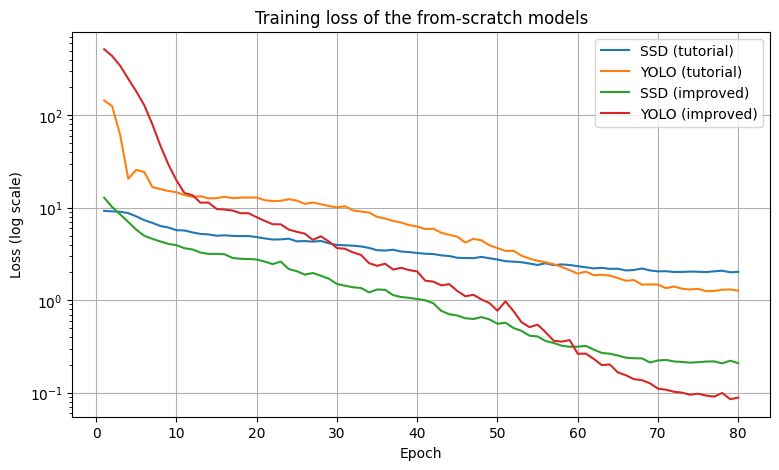

In [18]:
def conv_bn(in_ch, out_ch, k=3, act=None):
    return [nn.Conv2d(in_ch, out_ch, k, padding=k // 2, bias=False), nn.BatchNorm2d(out_ch),
            act if act is not None else nn.ReLU()]


# Improved SSD: batch normalization, 2 extra conv layers in the backbone, and a 4th scale (10x10) for large signs
def build_ssd_backbone_improved():
    return nn.Sequential(
        *conv_bn(3, 32), nn.MaxPool2d(2),
        *conv_bn(32, 64), *conv_bn(64, 64), nn.MaxPool2d(2),
        *conv_bn(64, 128), *conv_bn(128, 128)
    )


# Improved YOLO (Darknet style): batch normalization + LeakyReLU, extra 1x1 and 3x3 conv layers,
# and the last max-pool removed so the grid is 26x26 instead of 13x13 (better for small signs)
def build_yolo_backbone_improved():
    leaky = lambda: nn.LeakyReLU(0.1)
    return nn.Sequential(
        *conv_bn(3, 32, act=leaky()), nn.MaxPool2d(2),
        *conv_bn(32, 64, act=leaky()), nn.MaxPool2d(2),
        *conv_bn(64, 128, act=leaky()), *conv_bn(128, 64, 1, leaky()), *conv_bn(64, 128, act=leaky()), nn.MaxPool2d(2),
        *conv_bn(128, 256, act=leaky()), *conv_bn(256, 128, 1, leaky()), *conv_bn(128, 256, act=leaky()), nn.MaxPool2d(2),
        *conv_bn(256, 512, act=leaky()), *conv_bn(512, 256, 1, leaky()), *conv_bn(256, 512, act=leaky())
    )


ssd_improved = SSD(num_classes=num_classes + 1, num_boxes=6, num_scales=4,
                   backbone=build_ssd_backbone_improved(), batch_norm=True).to(device)
ssd_imp_anchors, ssd_imp_anchors_xyxy = ssd_anchors_for(ssd_improved)
print('Improved SSD feature maps:', ssd_improved.feature_sizes(300), '->', len(ssd_imp_anchors), 'boxes')
train_scratch('SSD (improved)', ssd_improved,
              lambda out, t: ssd_loss(out, t, ssd_imp_anchors, ssd_imp_anchors_xyxy),
              lambda m, x: ssd_predict(m, x, ssd_imp_anchors), ssd_train, ssd_test)

yolo_improved = YOLO(num_classes=num_classes, num_boxes=3, backbone=build_yolo_backbone_improved()).to(device)
with torch.no_grad():
    yolo_improved.eval()
    print('Improved YOLO output:', tuple(yolo_improved(torch.zeros(1, 3, 416, 416, device=device)).shape))
train_scratch('YOLO (improved)', yolo_improved,
              lambda out, t: yolo_loss(out, t, yolo_anchors),
              lambda m, x: yolo_predict(m, x, yolo_anchors), yolo_train, yolo_test)

plt.figure(figsize=(9, 5))
for name, history in histories.items():
    plt.plot(range(1, len(history) + 1), history, label=name)
plt.yscale('log')
plt.title('Training loss of the from-scratch models')
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.legend()
plt.grid()
plt.show()

## Block 19: Task 2 - Pretrained SSD (SSD300 VGG16, COCO): train and test

In [19]:
ssd_pretrained = ssd300_vgg16(weights=SSD300_VGG16_Weights.COCO_V1)
# New classification head for our classes (+1 for background); the backbone and box head keep their COCO weights
in_channels = retrieve_out_channels(ssd_pretrained.backbone, (300, 300))
num_anchors = ssd_pretrained.anchor_generator.num_anchors_per_location()
ssd_pretrained.head.classification_head = SSDClassificationHead(in_channels, num_anchors, num_classes + 1)
ssd_pretrained = ssd_pretrained.to(device)

epochs = 40
params = [p for p in ssd_pretrained.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.001, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
ssd_history = []
start = time.time()
print('Training: SSD300 (pretrained)')
for epoch in range(epochs):
    ssd_pretrained.train()
    total = 0.0
    for images, targets in train_loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss = sum(ssd_pretrained(images, targets).values())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item()
    scheduler.step()
    ssd_history.append(total / len(train_loader))
    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch + 1}/{epochs} - loss: {ssd_history[-1]:.4f}")
ssd_time = time.time() - start
histories['SSD300 VGG16 (pretrained)'] = ssd_history

ssd_pretrained.eval()
predictions = []
with torch.no_grad():
    for images, _ in test_loader:
        for out in ssd_pretrained([img.to(device) for img in images]):
            predictions.append({'boxes': out['boxes'].cpu().tolist(), 'scores': out['scores'].cpu().tolist(),
                                'labels': out['labels'].cpu().tolist()})
report('SSD300 VGG16 (pretrained)', predictions, sum(p.numel() for p in ssd_pretrained.parameters()), ssd_time)

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:01<00:00, 126MB/s]


Training: SSD300 (pretrained)
Epoch 1/40 - loss: 9.1053
Epoch 5/40 - loss: 3.1186
Epoch 10/40 - loss: 1.9846
Epoch 15/40 - loss: 1.3985
Epoch 20/40 - loss: 1.2026
Epoch 25/40 - loss: 0.9514
Epoch 30/40 - loss: 0.8757
Epoch 35/40 - loss: 0.8601
Epoch 40/40 - loss: 0.8491

SSD300 VGG16 (pretrained)
Class           Objects   AP@0.5  AP@0.75  Precision   Recall
crosswalk             8    0.527    0.169      1.000    0.125
speedlimit           22    0.909    0.852      0.889    0.727
stop                  4    0.185    0.185      0.167    0.250
trafficlight          3    0.351    0.351      1.000    0.333
mAP@0.5: 0.493   mAP@0.75: 0.389   (precision and recall at score >= 0.5)


## Block 20: Task 2 - Pretrained YOLO (YOLOv8n, COCO): train and test

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

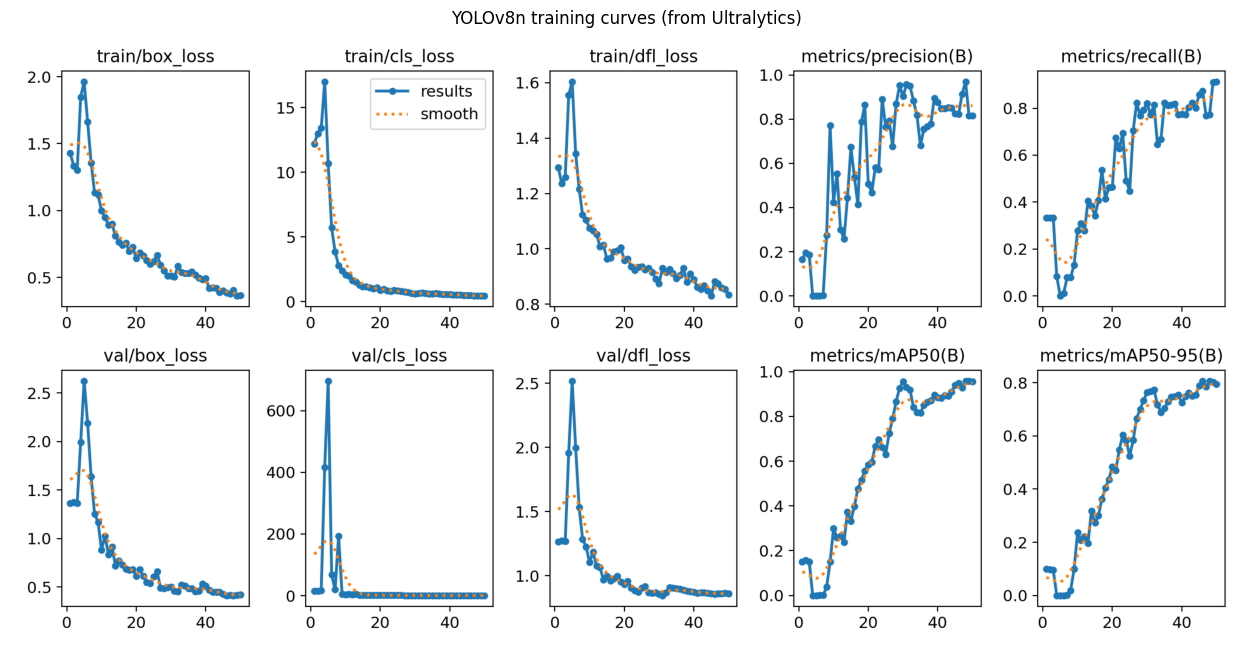

In [20]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
from ultralytics import YOLO as UltralyticsYOLO

# Write the same train/test split in YOLO format (one .txt per image: class x_center y_center width height)
yolo_dir = Path('/content/yolo_data')
shutil.rmtree(yolo_dir, ignore_errors=True)
for split, split_samples in (('train', train_samples), ('val', test_samples)):
    (yolo_dir / 'images' / split).mkdir(parents=True)
    (yolo_dir / 'labels' / split).mkdir(parents=True)
    for k, (img_path, objects) in enumerate(split_samples):
        img = open_image(img_path)
        w, h = img.size
        img.save(yolo_dir / 'images' / split / f'{split}_{k:04d}.png')
        lines = [f"{class_to_id[n] - 1} {(x1 + x2) / 2 / w:.6f} {(y1 + y2) / 2 / h:.6f} {(x2 - x1) / w:.6f} {(y2 - y1) / h:.6f}"
                 for n, (x1, y1, x2, y2) in objects]
        (yolo_dir / 'labels' / split / f'{split}_{k:04d}.txt').write_text('\n'.join(lines))
with open(yolo_dir / 'data.yaml', 'w') as f:
    yaml.safe_dump({'path': str(yolo_dir), 'train': 'images/train', 'val': 'images/val',
                    'names': {i: n for i, n in enumerate(class_names)}}, f)

yolo_pretrained = UltralyticsYOLO('yolov8n.pt')  # YOLOv8 nano, pretrained on COCO
start = time.time()
yolo_pretrained.train(data=str(yolo_dir / 'data.yaml'), epochs=50, imgsz=640, batch=16, seed=42,
                      project='/content/yolo_runs', name='road_signs', exist_ok=True, workers=2, verbose=False)
yolo_time = time.time() - start

# Test with the same evaluation functions as the other models
predictions = []
for img_path, _ in test_samples:
    r = yolo_pretrained.predict(str(img_path), conf=0.001, iou=0.6, imgsz=640, max_det=100, verbose=False)[0]
    predictions.append({'boxes': r.boxes.xyxy.cpu().tolist(), 'scores': r.boxes.conf.cpu().tolist(),
                        'labels': [int(c) + 1 for c in r.boxes.cls.cpu().tolist()]})
report('YOLOv8n (pretrained)', predictions, sum(p.numel() for p in yolo_pretrained.model.parameters()), yolo_time)

results_png = Path('/content/yolo_runs/road_signs/results.png')
if results_png.exists():
    plt.figure(figsize=(16, 8))
    plt.imshow(Image.open(results_png))
    plt.axis('off')
    plt.title('YOLOv8n training curves (from Ultralytics)')
    plt.show()

## Block 21: Summary of all models

Model                          Parameters  mAP@0.5  mAP@0.75  Train time (s)
SSD (tutorial)                    575,202    0.314     0.130            70.5
YOLO (tutorial)                 1,582,427    0.222     0.064           107.6
SSD (improved)                    970,744    0.457     0.283           104.7
YOLO (improved)                 3,306,427    0.413     0.246           163.0
SSD300 VGG16 (pretrained)      24,146,894    0.493     0.389           193.7
YOLOv8n (pretrained)            3,138,732    0.904     0.812           116.3

AP@0.5 per class:
Model                            crosswalk    speedlimit          stop  trafficlight
SSD (tutorial)                       0.183         0.779         0.292         0.002
YOLO (tutorial)                      0.000         0.557         0.333         0.000
SSD (improved)                       0.450         0.877         0.500         0.000
YOLO (improved)                      0.262         0.889         0.500         0.000
SSD300 VGG16 (pre

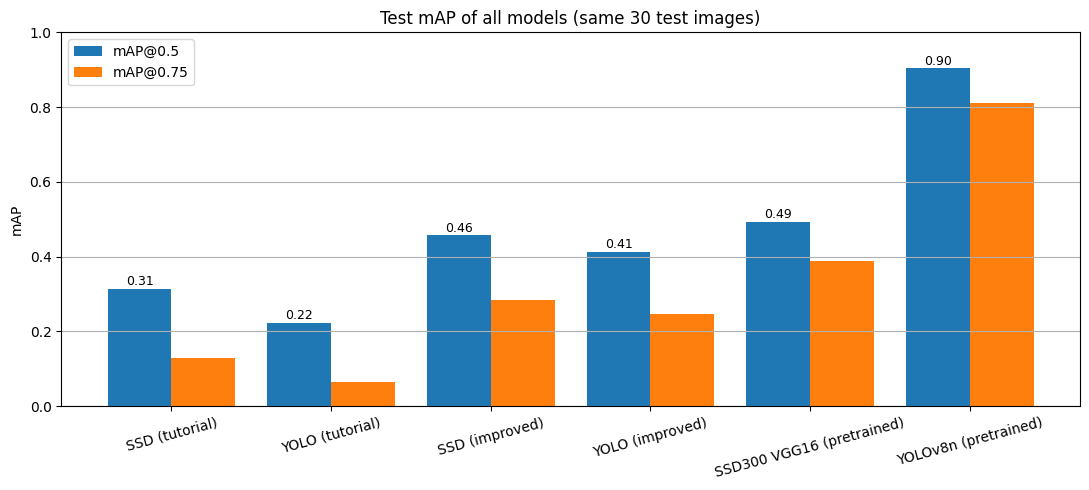

In [21]:
names = list(results)
print(f"{'Model':28} {'Parameters':>12} {'mAP@0.5':>8} {'mAP@0.75':>9} {'Train time (s)':>15}")
for n in names:
    r = results[n]
    print(f"{n:28} {r['params']:12,} {r['map50']:8.3f} {r['map75']:9.3f} {r['time']:15.1f}")

print(f"\nAP@0.5 per class:")
print(f"{'Model':28}" + ''.join(f"{c:>14}" for c in class_names))
for n in names:
    print(f"{n:28}" + ''.join(f"{results[n]['ap50'].get(c, float('nan')):14.3f}" for c in class_names))

x = np.arange(len(names))
plt.figure(figsize=(11, 5))
plt.bar(x - 0.2, [results[n]['map50'] for n in names], width=0.4, label='mAP@0.5')
plt.bar(x + 0.2, [results[n]['map75'] for n in names], width=0.4, label='mAP@0.75')
for i, n in enumerate(names):
    plt.text(i - 0.2, results[n]['map50'] + 0.01, f"{results[n]['map50']:.2f}", ha='center', fontsize=9)
plt.xticks(x, names, rotation=15)
plt.ylim(0, 1)
plt.ylabel('mAP')
plt.title('Test mAP of all models (same 30 test images)')
plt.legend()
plt.grid(axis='y')
plt.tight_layout()
plt.show()

## Block 22: Test images - ground truth vs predictions

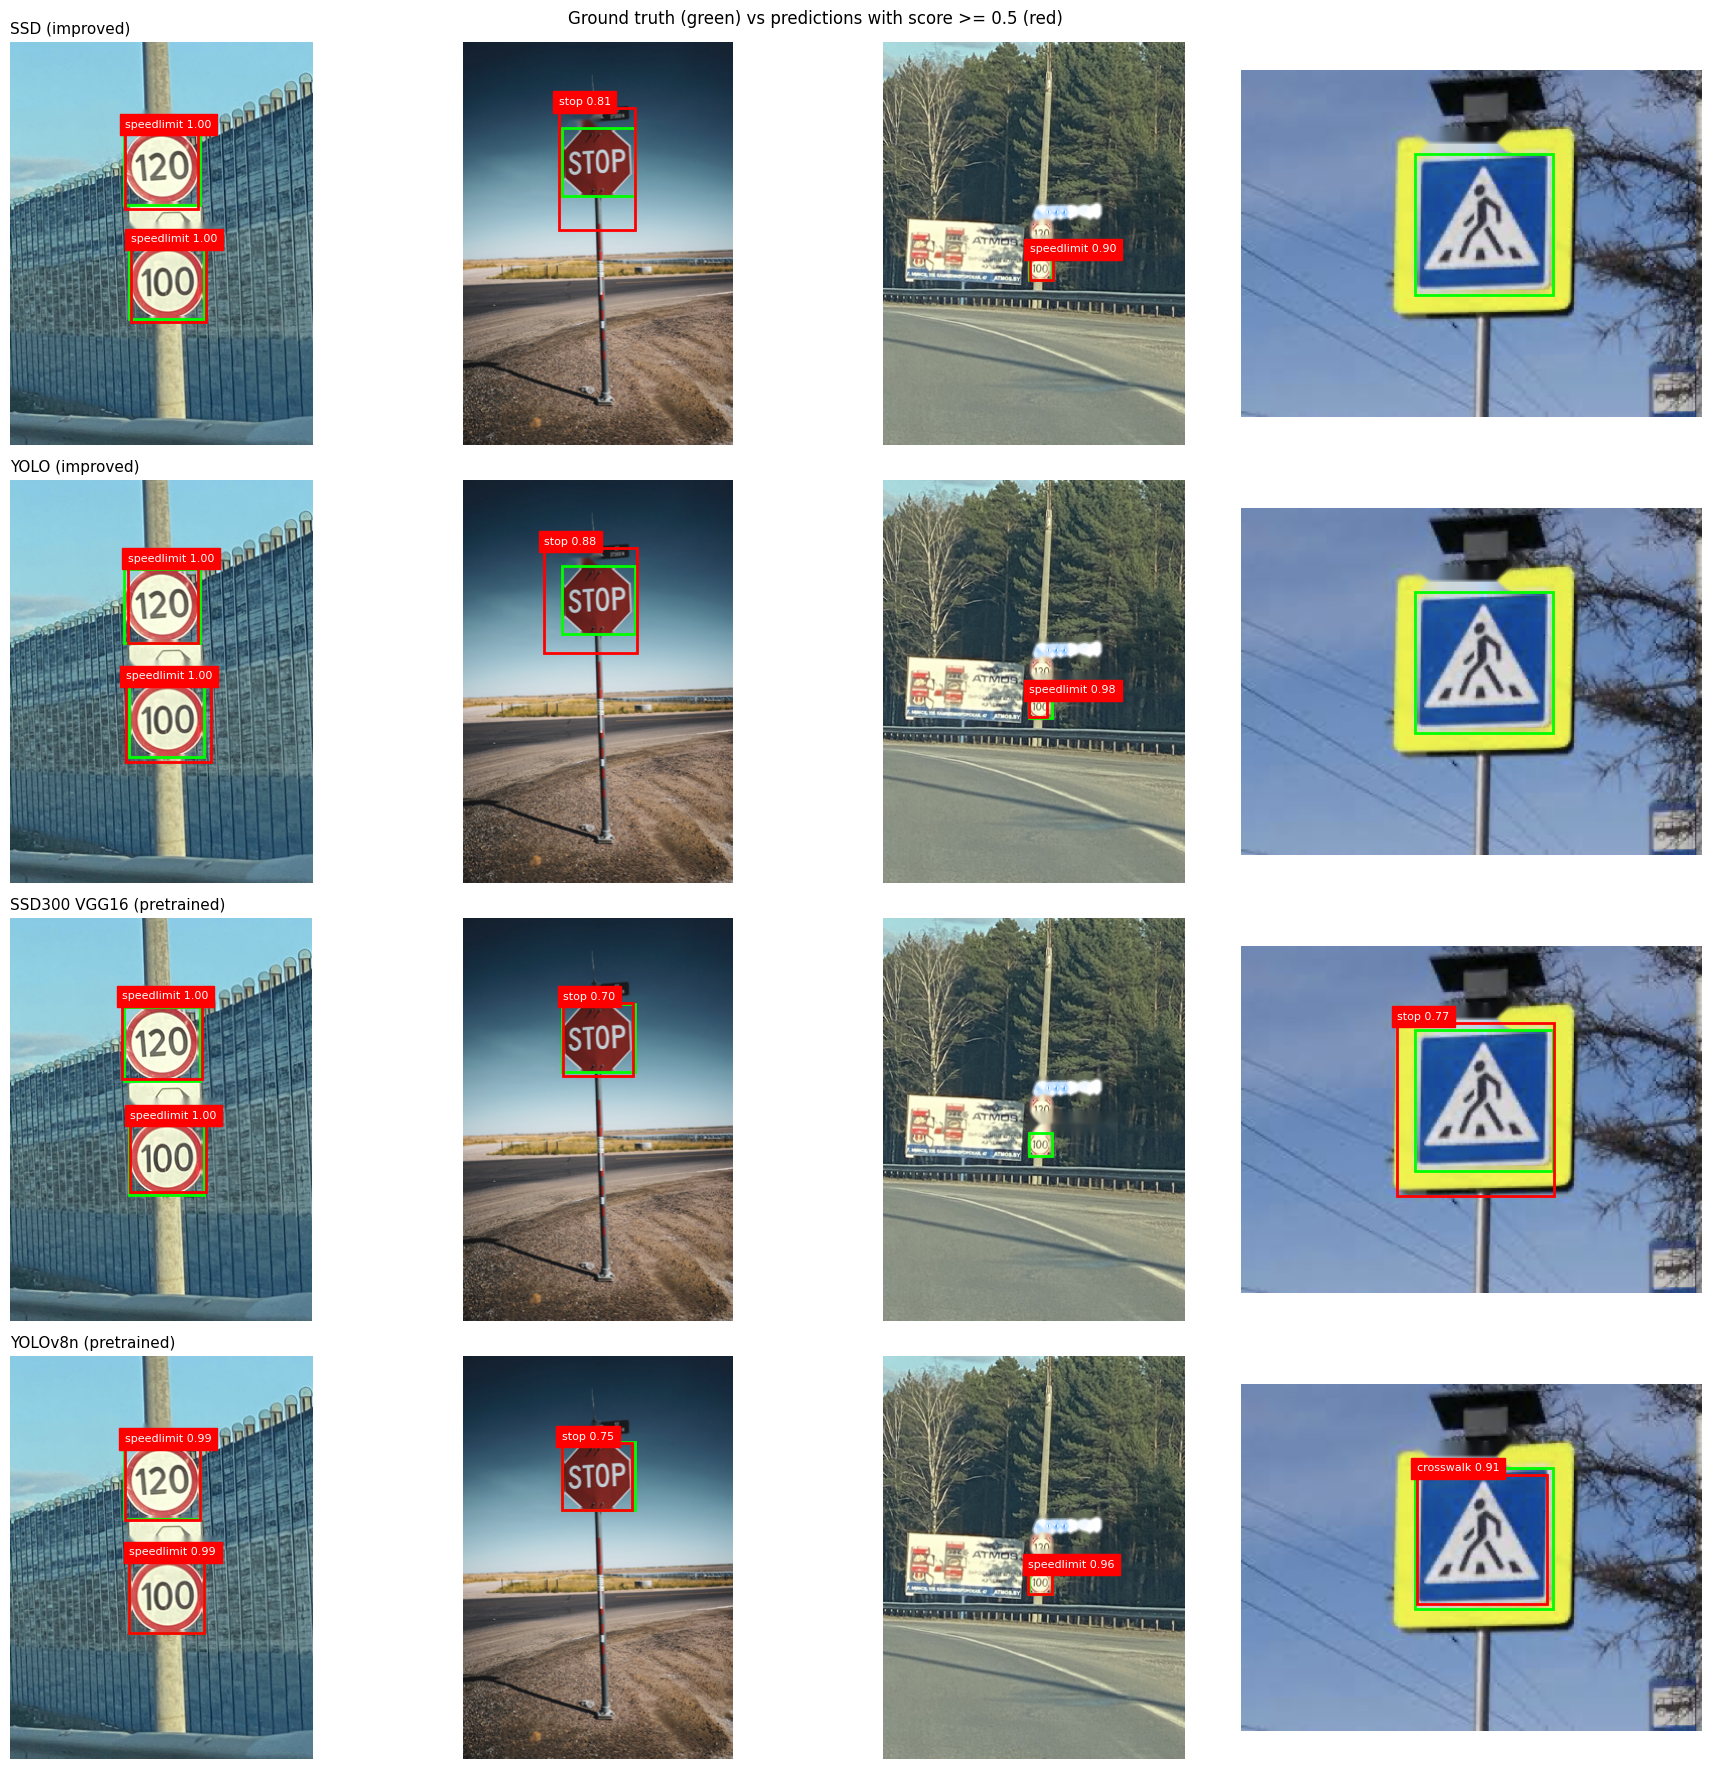

In [22]:
show = ['SSD (improved)', 'YOLO (improved)', 'SSD300 VGG16 (pretrained)', 'YOLOv8n (pretrained)']
show = [n for n in show if n in all_predictions]
picks = list(range(min(4, len(test_samples))))
plt.figure(figsize=(4.5 * len(picks), 4.5 * len(show)))
for r, name in enumerate(show):
    for c, idx in enumerate(picks):
        ax = plt.subplot(len(show), len(picks), r * len(picks) + c + 1)
        ax.imshow(open_image(test_samples[idx][0]))
        gt = test_ground_truths[idx]
        draw_boxes(ax, gt['boxes'], [''] * len(gt['boxes']), 'lime')
        pred = all_predictions[name][idx]
        keep = [k for k, s in enumerate(pred['scores']) if s >= 0.5]
        draw_boxes(ax, [pred['boxes'][k] for k in keep],
                   [f"{class_names[pred['labels'][k] - 1]} {pred['scores'][k]:.2f}" for k in keep], 'red')
        ax.axis('off')
        if c == 0:
            ax.set_title(name, loc='left', fontsize=11)
plt.suptitle('Ground truth (green) vs predictions with score >= 0.5 (red)')
plt.tight_layout()
plt.show()